# Praktikum 4 : PCA dan SVM pada teks ulasan

In [1]:
# Langkah 0 - Memuat ulasan pengganti citra wajah
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
data = pd.read_csv('../../dataset_pbl/reviews.csv').head(1000)
teks = data['text'].fillna('').to_numpy()
y = data['rating'].to_numpy(dtype=int)-1
print(data['rating'].value_counts())

rating
5.0    803
4.0    103
1.0     46
3.0     27
2.0     21
Name: count, dtype: int64


In [2]:
# Langkah 1 - Inspeksi teks
data[['text','rating']].head(15)

,text,rating
0,"Rekomendasi buat tempat ngopi, pisang goreng n...",5.0
1,"Teh susux enak, ngupi sambil melihat lalu lalang",5.0
2,tempat santai dan ena buat nongkrong rame rame,5.0
3,Resmi menamatkan Warkop Djayantie,5.0
4,Pisang goreng nya JUARA !\nharus coba pokoknya,5.0
5,Kopi dengan harga murah tapi rasa tidak murahan,5.0
6,syahdu bgt si tempatnya bikin candu pgn balik ...,5.0
7,"Pisgornya juara‼️enak banget ini mah, kopi but...",5.0
8,lokasinya di pasar dinoyo tp samsek ga bau pas...,5.0
9,Warung kopi yang terletak di pasar Dinoyo lant...,5.0


In [3]:
# Langkah 2 - Model PCA dan SVM sesuai contoh
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
pca = PCA(n_components=50, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')
model = make_pipeline(pca, svc)

In [4]:
# Langkah 3 - Split dan ekstraksi fitur teks
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
text_train, text_test, ytrain, ytest = train_test_split(teks, y, random_state=42)
vectorizer = CountVectorizer(max_features=150)
Xtrain = vectorizer.fit_transform(text_train).toarray()
Xtest = vectorizer.transform(text_test).toarray()

In [5]:
# Langkah 4 - Tuning sesuai contoh
from sklearn.model_selection import GridSearchCV
param_grid = {'svc__C':[1,5,10,50], 'svc__gamma':[0.0001,0.0005,0.001,0.005]}
grid = GridSearchCV(model, param_grid, n_jobs=1)
grid.fit(Xtrain, ytrain)
print(grid.best_params_)
print(grid.best_score_)

{'svc__C': 5, 'svc__gamma': 0.0001}
0.7746666666666666


In [6]:
model = grid.best_estimator_
yfit = model.predict(Xtest)

In [7]:
# Langkah 5 - Memeriksa prediksi
pd.DataFrame({'Teks':text_test, 'Rating aktual':ytest+1, 'Rating prediksi':yfit+1}).head(24)

,Teks,Rating aktual,Rating prediksi
0,"Pagi selepas subuh lewat agen bus ""Rosalia Ind...",5,5
1,"Terima kasih untuk ulasannya, ditunggu kedatan...",5,5
2,Pelayanan lama,1,5
3,Tempatnya nyaman. Cocok buat hangout dan nugas...,5,5
4,Mantap...,5,5
5,"tempatnya cocok bgt buat nugas, nongki bestt!!!",5,5
6,Salah satu tempat favoritku di Malang buat nug...,5,5
7,Trimakasih😊🙏🏻 …,5,5
8,"Cafe comfy di gang, cocok banget buat nongkron...",5,5
9,"Overall enak, beberapa feedback:\n- Nasinya ke...",4,2


In [8]:
# Langkah 6 - Evaluasi
from sklearn.metrics import classification_report
print(classification_report(ytest, yfit, labels=np.arange(5), target_names=['1','2','3','4','5'], zero_division=0))

              precision    recall  f1-score   support

           1       0.18      0.21      0.19        14
           2       0.00      0.00      0.00         4
           3       0.00      0.00      0.00        10
           4       0.50      0.04      0.08        24
           5       0.83      0.94      0.88       198

    accuracy                           0.76       250
   macro avg       0.30      0.24      0.23       250
weighted avg       0.71      0.76      0.71       250



Text(114.03333333333332, 0.5, 'Rating prediksi')

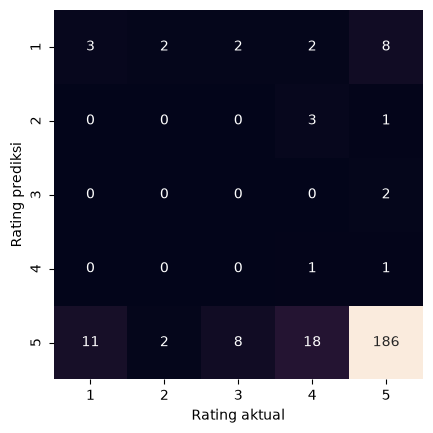

In [9]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
mat = confusion_matrix(ytest, yfit, labels=np.arange(5))
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=[1,2,3,4,5], yticklabels=[1,2,3,4,5])
plt.xlabel('Rating aktual')
plt.ylabel('Rating prediksi')